In [1]:
# First Python test

print("Hello! Welcome to E-commerce Sales Analytics.")

import sys

print("Python version:", sys.version)

Hello! Welcome to E-commerce Sales Analytics.
Python version: 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]


In [1]:
# Check our data analytics libraries

import sys
import pandas as pd
import numpy as np
import matplotlib
import seaborn as sns
import openpyxl

print("Python executable:", sys.executable)

print("\nLibrary versions:")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("OpenPyXL:", openpyxl.__version__)

print("\nAll libraries imported successfully!")

Python executable: c:\Users\Joydeep Boiragi\Documents\ecommerce-sales-analytics\.venv\Scripts\python.exe

Library versions:
Pandas: 3.1.1
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
OpenPyXL: 3.1.5

All libraries imported successfully!


In [1]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("\nLibraries imported successfully!")

Pandas version: 3.1.1
NumPy version: 2.5.4

Libraries imported successfully!


In [2]:
# Load the orders dataset

orders = pd.read_csv("data/raw/olist_orders_dataset.csv")

# Display the first 5 rows
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
# Check the number of rows and columns
print("Dataset Shape:", orders.shape)

# Check the column names
print("\nColumn Names:")
print(orders.columns.tolist())

Dataset Shape: (99441, 8)

Column Names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


In [4]:
# Understand the dataset information
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [5]:
# Check the distribution of order statuses

print("Order Status Distribution:")

print(orders['order_status'].value_counts())

Order Status Distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [6]:
# Calculate delivered order percentage

total_orders = len(orders)

delivered_orders = (orders['order_status'] == 'delivered').sum()

delivery_percentage = (delivered_orders / total_orders) * 100

print("Total Orders:", total_orders)

print("Delivered Orders:", delivered_orders)

print("Delivery Percentage:", round(delivery_percentage, 2), "%")

Total Orders: 99441
Delivered Orders: 96478
Delivery Percentage: 97.02 %


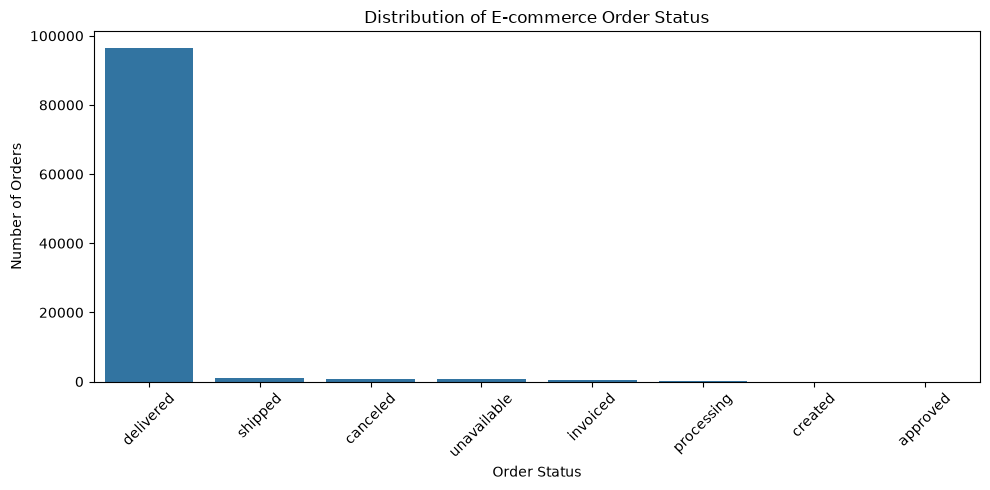

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count order statuses
status_counts = orders['order_status'].value_counts()

# Create bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)

plt.title("Distribution of E-commerce Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [8]:
# Convert purchase timestamp into datetime format

orders['order_purchase_timestamp'] = pd.to_datetime(
    orders['order_purchase_timestamp']
)

# Check the data type
print("Updated Data Type:")

print(orders['order_purchase_timestamp'].dtype)

# Display first five purchase dates
print("\nFirst 5 Purchase Dates:")

print(orders['order_purchase_timestamp'].head())


Updated Data Type:
datetime64[us]

First 5 Purchase Dates:
0   2017-10-02 10:56:33
1   2018-07-24 20:41:37
2   2018-08-08 08:38:49
3   2017-11-18 19:28:06
4   2018-02-13 21:18:39
Name: order_purchase_timestamp, dtype: datetime64[us]


In [9]:
# Extract year and month

orders['order_month'] = (
    orders['order_purchase_timestamp'].dt.to_period('M')
)

# Count monthly orders

monthly_orders = orders['order_month'].value_counts().sort_index()

# Display monthly orders

print("Monthly Order Trends:")
print(monthly_orders)

Monthly Order Trends:
order_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64


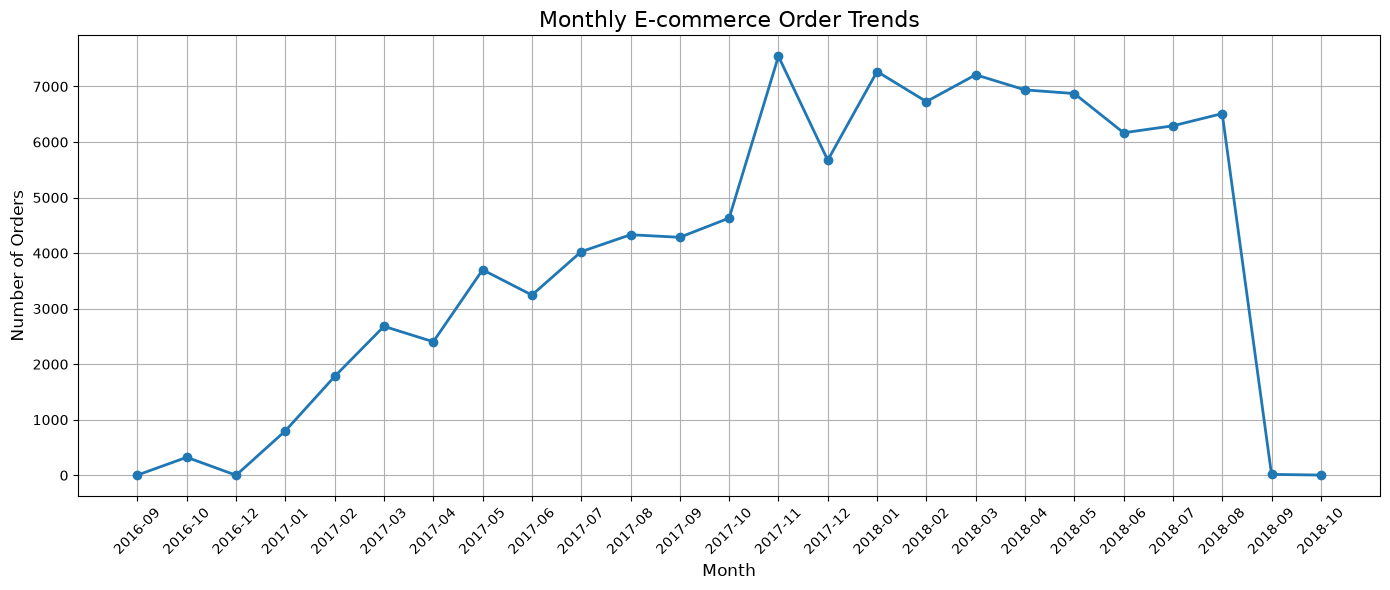

In [10]:
# Create monthly order trend visualization

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_orders.index.astype(str),
    monthly_orders.values,
    marker='o',
    linewidth=2
)

plt.title("Monthly E-commerce Order Trends", fontsize=16)

plt.xlabel("Month", fontsize=12)

plt.ylabel("Number of Orders", fontsize=12)

plt.xticks(rotation=45)

plt.grid(True)

plt.tight_layout()

plt.show()

In [11]:
# Load the order items dataset

order_items = pd.read_csv(
    "data/raw/olist_order_items_dataset.csv"
)

# Display the first 5 rows

order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [12]:
# Check dataset dimensions

print("Dataset Shape:", order_items.shape)

# Check column names

print("\nColumn Names:")

print(order_items.columns.tolist())

Dataset Shape: (112650, 7)

Column Names:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


In [13]:
# Understand order items dataset

order_items.info()

# Check missing values

print("\nMissing Values:")
print(order_items.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB

Missing Values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


In [14]:
# Calculate total product revenue

total_revenue = order_items['price'].sum()

# Calculate total shipping charges

total_shipping = order_items['freight_value'].sum()

# Calculate combined value

total_order_value = total_revenue + total_shipping

# Calculate average product price

average_price = order_items['price'].mean()

# Display results

print("Total Product Revenue: R$", round(total_revenue, 2))

print("Total Shipping Charges: R$", round(total_shipping, 2))

print("Total Order Item Value: R$", round(total_order_value, 2))

print("Average Product Price: R$", round(average_price, 2))

Total Product Revenue: R$ 13591643.7
Total Shipping Charges: R$ 2251909.54
Total Order Item Value: R$ 15843553.24
Average Product Price: R$ 120.65


In [15]:
# Merge order items with order dates

sales_data = order_items.merge(
    orders[['order_id', 'order_purchase_timestamp']],
    on='order_id',
    how='left'
)

# Check the merged dataset

print("Merged Dataset Shape:", sales_data.shape)

sales_data.head()

Merged Dataset Shape: (112650, 8)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51


In [16]:
# Extract purchase month

sales_data['order_month'] = (
    sales_data['order_purchase_timestamp'].dt.to_period('M')
)

# Calculate monthly revenue

monthly_revenue = sales_data.groupby('order_month').agg(
    product_revenue=('price', 'sum'),
    shipping_revenue=('freight_value', 'sum')
)

# Calculate combined value

monthly_revenue['total_value'] = (
    monthly_revenue['product_revenue']
    + monthly_revenue['shipping_revenue']
)

# Display results

print("Monthly Revenue Analysis:")

print(monthly_revenue.round(2))

Monthly Revenue Analysis:
             product_revenue  shipping_revenue  total_value
order_month                                                
2016-09               267.36             87.39       354.75
2016-10             49507.66           7301.18     56808.84
2016-12                10.90              8.72        19.62
2017-01            120312.87          16875.62    137188.49
2017-02            247303.02          38977.60    286280.62
2017-03            374344.30          57704.29    432048.59
2017-04            359927.23          52495.01    412422.24
2017-05            506071.14          80119.81    586190.95
2017-06            433038.60          69924.44    502963.04
2017-07            498031.48          86940.14    584971.62
2017-08            573971.68          94232.92    668204.60
2017-09            624401.69          95997.22    720398.91
2017-10            664219.43         105092.94    769312.37
2017-11           1010271.37         168872.40   1179143.77
2017-12       

In [17]:
# Verify monthly revenue totals

print("Revenue Verification")

print(
    "Product Revenue:",
    round(monthly_revenue['product_revenue'].sum(), 2)
)

print(
    "Shipping Revenue:",
    round(monthly_revenue['shipping_revenue'].sum(), 2)
)

print(
    "Combined Revenue:",
    round(monthly_revenue['total_value'].sum(), 2)
)

print("\nOriginal Product Revenue:", round(total_revenue, 2))

print("Original Shipping Revenue:", round(total_shipping, 2))

Revenue Verification
Product Revenue: 13591643.7
Shipping Revenue: 2251909.54
Combined Revenue: 15843553.24

Original Product Revenue: 13591643.7
Original Shipping Revenue: 2251909.54
